# CuZn order-disorder transition: Metropolis analysis

This notebook uses the rigid-lattice Monte Carlo model of `src/model.py`:

- bcc lattice of $6 \times 6 \times 6$ cells, $N = 432$ sites, periodic boundary conditions;
- pair energies $J$ (1st neighbours) and $I$ (2nd neighbours) from the project description;
- Metropolis algorithm with exchanges of two 1st-neighbour atoms.

Units: energies in eV, temperatures in K.
One **sweep** = $N = 432$ exchange attempts (each atom gets on average one chance to move). The functions of `model.py` count in **steps** (single attempts), so we pass `n_sweeps * SWEEP`.

Plan:
1. checks at $T = 0$ K and cohesive energy;
2. number of steps needed to reach equilibrium (`metropolis_before_eq`);
3. temperature scan with `metropolis`: energy, heat capacity, long-range order $\eta$, Cowley parameters $\alpha_1, \alpha_2$;
4. estimate of the transition temperature.

In [1]:
import sys
import math
import random

import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, "src")
import model

random.seed(2026)     # model.py uses the global random module: fixed seed = reproducible notebook
np.random.seed(2026)  # used below to build random (fully disordered) lattices

N = model.NB_SITES
SWEEP = model.NB_SITES  # 1 sweep = NB_SITES exchange attempts

## 1. Checks at $T = 0$ K and cohesive energy

At $T = 0$ K the structure is the perfect B2 order (Cu on the corners $\alpha$, Zn on the centres $\beta$).
Each atom has 8 first neighbours, all of the other species, and its 6 second neighbours are of its own species ($I_{\text{CuCu}} = I_{\text{ZnZn}} = 0$). Counting each pair once:

$$\frac{E}{N} = \frac{8}{2} J_{\text{CuZn}} = 4 \times (-0.621) = -2.484 \text{ eV/atom}$$

We also expect $\alpha_1 = -1$ (only Zn around a Cu), $\alpha_2 = +1$ (no Zn in the second shell) and $\eta = 1$.

In [2]:
model.init_at_t0()
E0 = model.get_full_energy()
alpha_1, alpha_2 = model.cowley()
eta = model.order_parameter()

print(f"E(B2) = {E0:.3f} eV for {N} atoms")
print(f"Cohesive energy at T = 0 K: {E0 / N:.4f} eV/atom")
print(f"Cowley parameters: alpha_1 = {alpha_1:+.3f}, alpha_2 = {alpha_2:+.3f}  (expected -1, +1)")
print(f"Long-range order parameter: eta = {eta:.3f}  (expected 1)")

assert abs(E0 / N + 2.484) < 1e-9
assert abs(alpha_1 + 1) < 1e-12 and abs(alpha_2 - 1) < 1e-12 and eta == 1

E(B2) = -1073.088 eV for 432 atoms
Cohesive energy at T = 0 K: -2.4840 eV/atom
Cowley parameters: alpha_1 = -1.000, alpha_2 = +1.000  (expected -1, +1)
Long-range order parameter: eta = 1.000  (expected 1)


## 2. Number of steps needed to reach equilibrium

`metropolis` starts from the perfect B2 structure, so the first steps are not representative of the temperature $T$: the system needs some time to "forget" its initial state. We measure this time with `metropolis_before_eq`, which returns the energy after every step.

For each temperature:
- the energy is averaged over each sweep to reduce the noise;
- the **equilibrium value** $E_{eq}$ and its fluctuation $\sigma$ are the mean and standard deviation over the second half of the run;
- equilibrium is considered reached when the running mean over 10 sweeps comes within $\sigma$ of $E_{eq}$.

In [3]:
T_EQ = [300, 600, 700, 750, 800, 1000, 1500]
N_SWEEPS_TEST = 400


def relaxation_sweeps(per_sweep: np.ndarray, window: int = 10) -> int:
    # Number of sweeps after which the running mean stays close to the equilibrium value
    half = len(per_sweep) // 2
    value_eq = per_sweep[half:].mean()
    sigma = per_sweep[half:].std()
    running = np.convolve(per_sweep, np.ones(window) / window, mode="valid")  # running[k] = mean of sweeps k..k+window-1
    close = np.abs(running - value_eq) <= sigma
    if not close.any():
        return len(per_sweep)
    return int(np.argmax(close)) + window


energy_runs = {}
energy_per_sweep = {}
n_eq_energy = {}
for T in T_EQ:
    energies = np.array(model.metropolis_before_eq(N_SWEEPS_TEST * SWEEP, T)) / N  # eV/atom, one value per step
    energy_runs[T] = energies
    energy_per_sweep[T] = energies.reshape(N_SWEEPS_TEST, SWEEP).mean(axis=1)
    n_eq_energy[T] = relaxation_sweeps(energy_per_sweep[T])
    print(f"T = {T:5d} K: E_eq = {energy_per_sweep[T][N_SWEEPS_TEST // 2:].mean():.4f} eV/atom, "
          f"equilibrium reached after {n_eq_energy[T]:3d} sweeps = {n_eq_energy[T] * SWEEP} steps")

T =   300 K: E_eq = -2.4840 eV/atom, equilibrium reached after  10 sweeps = 4320 steps


T =   600 K: E_eq = -2.4719 eV/atom, equilibrium reached after  24 sweeps = 10368 steps


T =   700 K: E_eq = -2.4619 eV/atom, equilibrium reached after  16 sweeps = 6912 steps


T =   750 K: E_eq = -2.4562 eV/atom, equilibrium reached after  24 sweeps = 10368 steps


T =   800 K: E_eq = -2.4528 eV/atom, equilibrium reached after  19 sweeps = 8208 steps


T =  1000 K: E_eq = -2.4500 eV/atom, equilibrium reached after  14 sweeps = 6048 steps


T =  1500 K: E_eq = -2.4481 eV/atom, equilibrium reached after  12 sweeps = 5184 steps


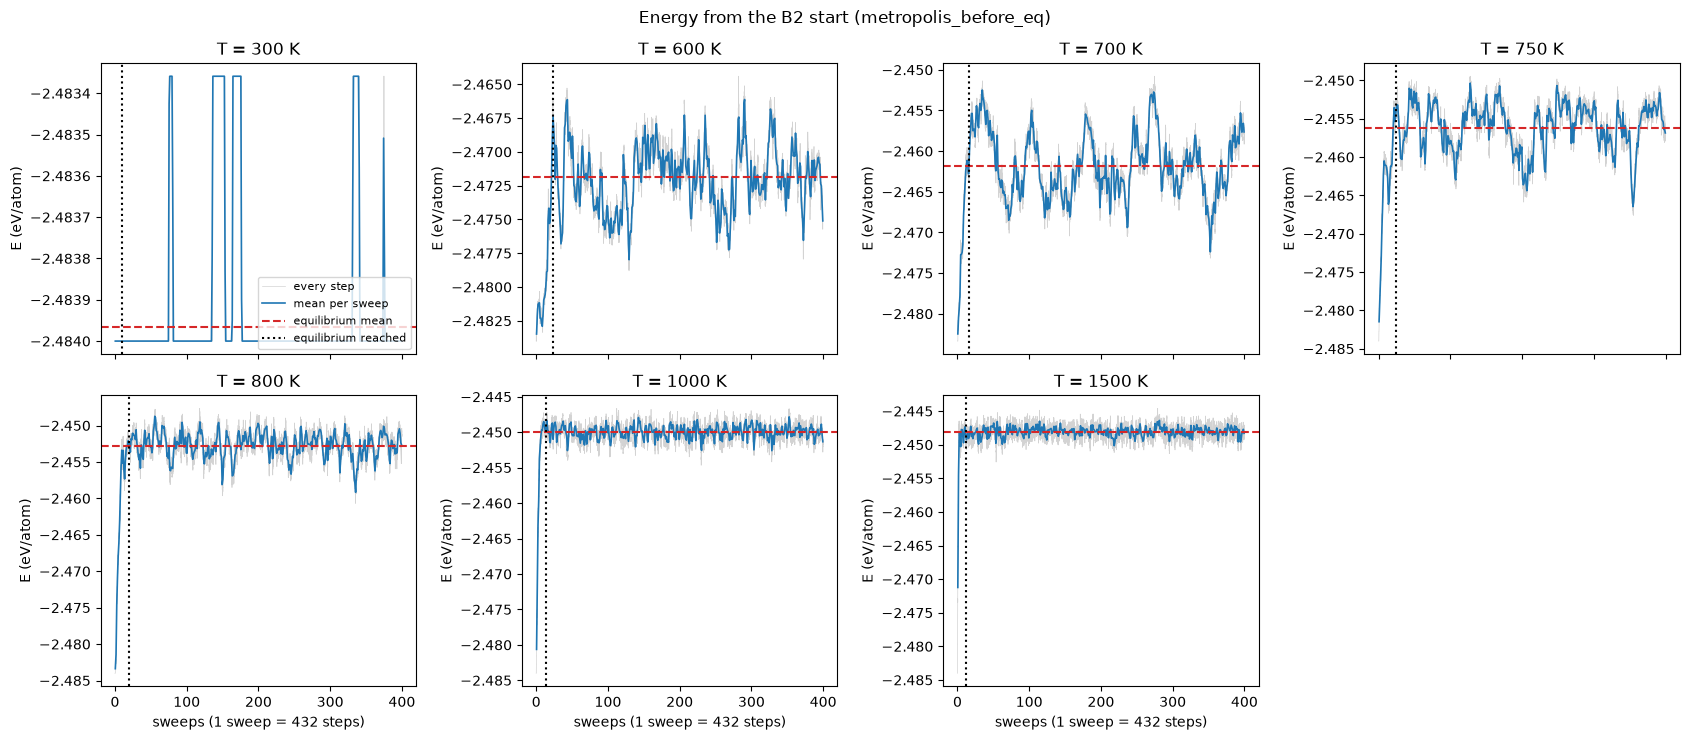

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(17, 7.5), sharex=True)
for ax, T in zip(axes.flat, T_EQ):
    energies = energy_runs[T]
    per_sweep = energy_per_sweep[T]
    E_eq = per_sweep[N_SWEEPS_TEST // 2:].mean()
    ax.plot(np.arange(len(energies)) / SWEEP, energies, color="lightgray", lw=0.5, label="every step")
    ax.plot(np.arange(N_SWEEPS_TEST) + 0.5, per_sweep, color="C0", lw=1.2, label="mean per sweep")
    ax.axhline(E_eq, color="C3", ls="--", label="equilibrium mean")
    ax.axvline(n_eq_energy[T], color="k", ls=":", label="equilibrium reached")
    ax.set_title(f"T = {T} K")
    ax.set_ylabel("E (eV/atom)")
    ax.ticklabel_format(axis="y", useOffset=False)
for ax in axes[1]:
    ax.set_xlabel("sweeps (1 sweep = 432 steps)")
axes.flat[-1].axis("off")
axes.flat[0].legend(loc="lower right", fontsize=8)
fig.suptitle("Energy from the B2 start (metropolis_before_eq)")
fig.tight_layout()
plt.show()

The energy starts at the B2 value $-2.484$ eV/atom and increases until it fluctuates around its equilibrium value.
At low temperature the B2 start is already (almost) at equilibrium; at high temperature the disorder sets in within a few sweeps. The slowest relaxation is at intermediate temperatures, below and around the transition.

The energy is not the only quantity that must be equilibrated: the order parameter $\eta$ can relax more slowly near the transition (large, slow fluctuations of the order). We check it with `metropolis` itself, using `n_until_eq = 0` and one measurement per sweep, which gives the evolution of $|\eta|$ from the B2 start.

T =   300 K: |eta|_eq = 1.000, equilibrium reached after  10 sweeps


T =   600 K: |eta|_eq = 0.818, equilibrium reached after  57 sweeps


T =   700 K: |eta|_eq = 0.606, equilibrium reached after  15 sweeps


T =   750 K: |eta|_eq = 0.221, equilibrium reached after  43 sweeps


T =   800 K: |eta|_eq = 0.137, equilibrium reached after  22 sweeps


T =  1000 K: |eta|_eq = 0.081, equilibrium reached after  14 sweeps


T =  1500 K: |eta|_eq = 0.062, equilibrium reached after  12 sweeps


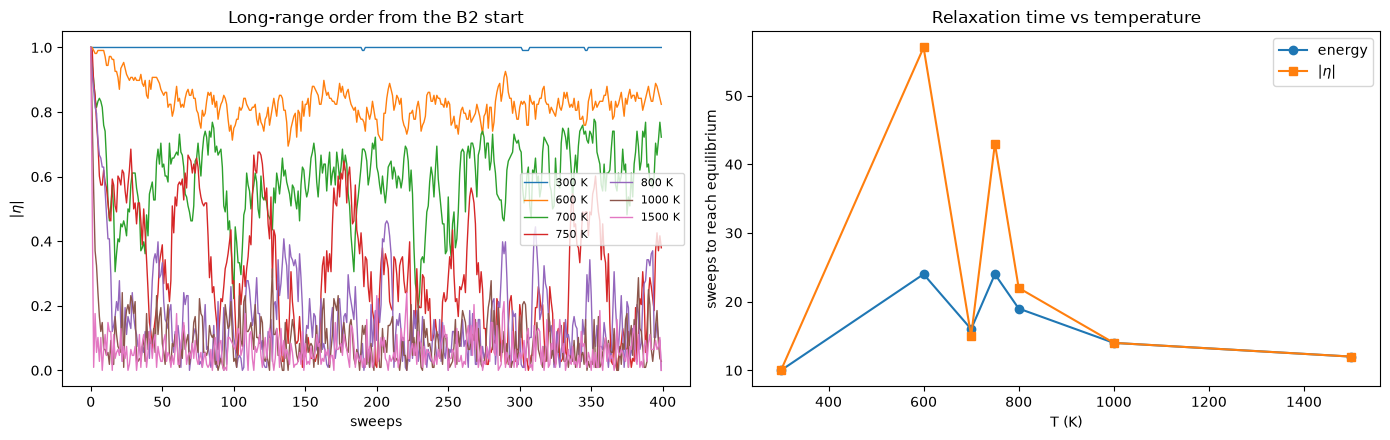

In [5]:
eta_per_sweep = {}
n_eq_eta = {}
for T in T_EQ:
    _, eta, _, _ = model.metropolis(0, N_SWEEPS_TEST * SWEEP, T, measure_every=SWEEP)
    eta_per_sweep[T] = eta
    n_eq_eta[T] = relaxation_sweeps(eta)
    print(f"T = {T:5d} K: |eta|_eq = {eta[N_SWEEPS_TEST // 2:].mean():.3f}, equilibrium reached after {n_eq_eta[T]:3d} sweeps")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for T in T_EQ:
    ax[0].plot(np.arange(N_SWEEPS_TEST), eta_per_sweep[T], lw=1, label=f"{T} K")
ax[0].set_xlabel("sweeps")
ax[0].set_ylabel(r"$|\eta|$")
ax[0].set_title(r"Long-range order from the B2 start")
ax[0].legend(fontsize=8, ncol=2)

ax[1].plot(T_EQ, [n_eq_energy[T] for T in T_EQ], "o-", label="energy")
ax[1].plot(T_EQ, [n_eq_eta[T] for T in T_EQ], "s-", label=r"$|\eta|$")
ax[1].set_xlabel("T (K)")
ax[1].set_ylabel("sweeps to reach equilibrium")
ax[1].set_title("Relaxation time vs temperature")
ax[1].legend()
fig.tight_layout()
plt.show()

**Choice of the equilibration length.** We take the slowest relaxation found above (energy or $|\eta|$), multiply it by 2 as a safety margin, and round it up to a multiple of 50 sweeps. This value is used for every temperature of the scan.

In [6]:
n_eq_max = max(max(n_eq_energy.values()), max(n_eq_eta.values()))
N_EQ = math.ceil(2 * n_eq_max / 50) * 50
print(f"Slowest relaxation: {n_eq_max} sweeps")
print(f"Equilibration used for the scan: N_EQ = {N_EQ} sweeps = {N_EQ * SWEEP} steps")

Slowest relaxation: 57 sweeps
Equilibration used for the scan: N_EQ = 150 sweeps = 64800 steps


## 3. Temperature scan

For each temperature, `metropolis` runs `N_EQ` sweeps without measuring, then `N_MEAS` sweeps with one measurement per sweep (`measure_every=SWEEP`). Consecutive steps differ by at most two atoms, so measuring more often would cost a lot of time without adding information. The whole scan takes a few minutes.

From the measured series we compute:
- the mean energy per atom $\langle E \rangle / N$;
- the heat capacity per atom from the energy fluctuations, in units of $k_B$: $\dfrac{C}{N k_B} = \dfrac{\langle E^2 \rangle - \langle E \rangle^2}{N (k_B T)^2}$;
- $\langle |\eta| \rangle$ and $\langle \eta^2 \rangle$ (the absolute value is needed because near $T_c$ the order can flip between "Cu on $\alpha$" and "Cu on $\beta$");
- $\langle \alpha_1 \rangle$, $\langle \alpha_2 \rangle$.

Error bars are $\sigma / \sqrt{n}$ over the measurements. Consecutive sweeps are correlated, so they underestimate the real uncertainty, especially near $T_c$.

In [7]:
N_MEAS = 800
T_SCAN = [200, 300, 400, 500, 550, 600, 650, 675, 700, 725, 750, 775, 800, 850, 900, 1000, 1200, 1600]

series = {}
for T in T_SCAN:
    series[T] = model.metropolis(N_EQ * SWEEP, N_MEAS * SWEEP, T, measure_every=SWEEP)
    energies, eta, alpha_1, alpha_2 = series[T]
    print(f"T = {T:5d} K: E = {energies.mean() / N:.4f} eV/atom, |eta| = {eta.mean():.3f}, "
          f"alpha_1 = {alpha_1.mean():+.3f}, alpha_2 = {alpha_2.mean():+.3f}")

T =   200 K: E = -2.4840 eV/atom, |eta| = 1.000, alpha_1 = -1.000, alpha_2 = +1.000


T =   300 K: E = -2.4840 eV/atom, |eta| = 1.000, alpha_1 = -1.000, alpha_2 = +0.999


T =   400 K: E = -2.4827 eV/atom, |eta| = 0.982, alpha_1 = -0.966, alpha_2 = +0.965


T =   500 K: E = -2.4780 eV/atom, |eta| = 0.915, alpha_1 = -0.845, alpha_2 = +0.840


T =   550 K: E = -2.4757 eV/atom, |eta| = 0.878, alpha_1 = -0.786, alpha_2 = +0.778


...

T =   850 K: E = -2.4516 eV/atom, |eta| = 0.131, alpha_1 = -0.169, alpha_2 = +0.117


T =   900 K: E = -2.4508 eV/atom, |eta| = 0.102, alpha_1 = -0.148, alpha_2 = +0.097


T =  1000 K: E = -2.4500 eV/atom, |eta| = 0.086, alpha_1 = -0.126, alpha_2 = +0.080


T =  1200 K: E = -2.4489 eV/atom, |eta| = 0.067, alpha_1 = -0.098, alpha_2 = +0.053


T =  1600 K: E = -2.4478 eV/atom, |eta| = 0.055, alpha_1 = -0.066, alpha_2 = +0.030


In [8]:
T_arr = np.array(T_SCAN, dtype=float)
n_meas = len(series[T_SCAN[0]][0])

E_mean = np.array([series[T][0].mean() for T in T_SCAN]) / N
E_err = np.array([series[T][0].std() for T in T_SCAN]) / N / np.sqrt(n_meas)
C = np.array([series[T][0].var() for T in T_SCAN]) / (model.kB * T_arr) ** 2 / N
eta_mean = np.array([series[T][1].mean() for T in T_SCAN])
eta_err = np.array([series[T][1].std() for T in T_SCAN]) / np.sqrt(n_meas)
eta2_mean = np.array([(series[T][1] ** 2).mean() for T in T_SCAN])
alpha_1_mean = np.array([series[T][2].mean() for T in T_SCAN])
alpha_1_err = np.array([series[T][2].std() for T in T_SCAN]) / np.sqrt(n_meas)
alpha_2_mean = np.array([series[T][3].mean() for T in T_SCAN])
alpha_2_err = np.array([series[T][3].std() for T in T_SCAN]) / np.sqrt(n_meas)

# |eta| of a fully random lattice: finite-size floor, |eta| never reaches 0 in a box of 432 sites
random_eta = []
for _ in range(2000):
    np.random.shuffle(model.sous_reseau)
    random_eta.append(abs(model.order_parameter()))
eta_random = np.mean(random_eta)
print(f"<|eta|> of a random lattice: {eta_random:.3f}")

<|eta|> of a random lattice: 0.039


### Energy, heat capacity and order parameters

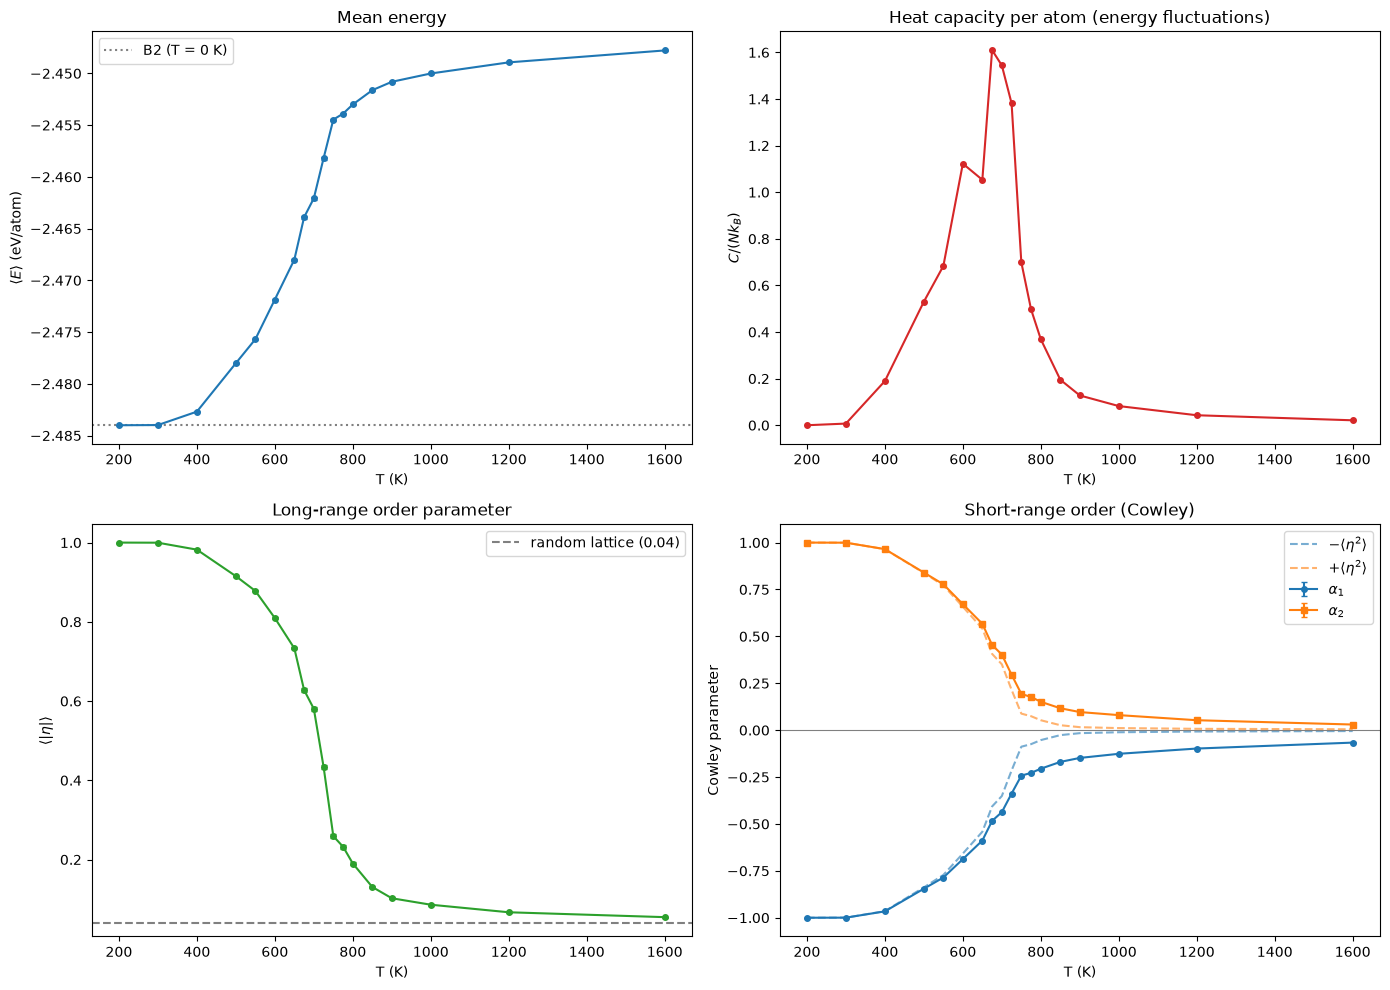

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

ax = axes[0, 0]
ax.errorbar(T_arr, E_mean, yerr=E_err, fmt="o-", ms=4, capsize=2)
ax.axhline(E0 / N, color="gray", ls=":", label="B2 (T = 0 K)")
ax.set_xlabel("T (K)")
ax.set_ylabel(r"$\langle E \rangle$ (eV/atom)")
ax.set_title("Mean energy")
ax.legend()

ax = axes[0, 1]
ax.plot(T_arr, C, "o-", ms=4, color="C3")
ax.set_xlabel("T (K)")
ax.set_ylabel(r"$C / (N k_B)$")
ax.set_title("Heat capacity per atom (energy fluctuations)")

ax = axes[1, 0]
ax.errorbar(T_arr, eta_mean, yerr=eta_err, fmt="o-", ms=4, capsize=2, color="C2")
ax.axhline(eta_random, color="gray", ls="--", label=f"random lattice ({eta_random:.2f})")
ax.set_xlabel("T (K)")
ax.set_ylabel(r"$\langle |\eta| \rangle$")
ax.set_title("Long-range order parameter")
ax.legend()

ax = axes[1, 1]
ax.errorbar(T_arr, alpha_1_mean, yerr=alpha_1_err, fmt="o-", ms=4, capsize=2, color="C0", label=r"$\alpha_1$")
ax.errorbar(T_arr, alpha_2_mean, yerr=alpha_2_err, fmt="s-", ms=4, capsize=2, color="C1", label=r"$\alpha_2$")
ax.plot(T_arr, -eta2_mean, "--", color="C0", alpha=0.6, label=r"$-\langle \eta^2 \rangle$")
ax.plot(T_arr, eta2_mean, "--", color="C1", alpha=0.6, label=r"$+\langle \eta^2 \rangle$")
ax.axhline(0, color="gray", lw=0.8)
ax.set_xlabel("T (K)")
ax.set_ylabel("Cowley parameter")
ax.set_title("Short-range order (Cowley)")
ax.legend()

fig.tight_layout()
plt.show()

**Reading the Cowley plot.** If the only order in the crystal were the long-range order, a Cu on $\alpha$ would see a fraction $(1+\eta)/2$ of Zn on the $\beta$ sublattice, and a Cu on $\beta$ a fraction $(1-\eta)/2$. This gives $\alpha_1 = -\eta^2$ and $\alpha_2 = +\eta^2$ (dashed lines).
- Below $T_c$ the Cowley parameters follow these curves: the long-range order explains almost all of the local order.
- Above $T_c$, $\eta^2 \approx 0$ but $\alpha_1$ stays clearly negative: Cu atoms still prefer Zn first neighbours. This is **short-range order**, which survives the loss of long-range order and fades slowly as $T$ increases.

## 4. Transition temperature

Two estimates of $T_c$ from the scan:
- the maximum of the heat capacity;
- the temperature where $\langle |\eta| \rangle$ drops the fastest (minimum of $d\langle|\eta|\rangle/dT$).

In [10]:
Tc_C = T_arr[np.argmax(C)]
Tc_eta = T_arr[np.argmin(np.gradient(eta_mean, T_arr))]
print(f"Tc from the heat capacity peak:      {Tc_C:.0f} K")
print(f"Tc from the steepest drop of |eta|:  {Tc_eta:.0f} K")

Tc from the heat capacity peak:      675 K
Tc from the steepest drop of |eta|:  725 K


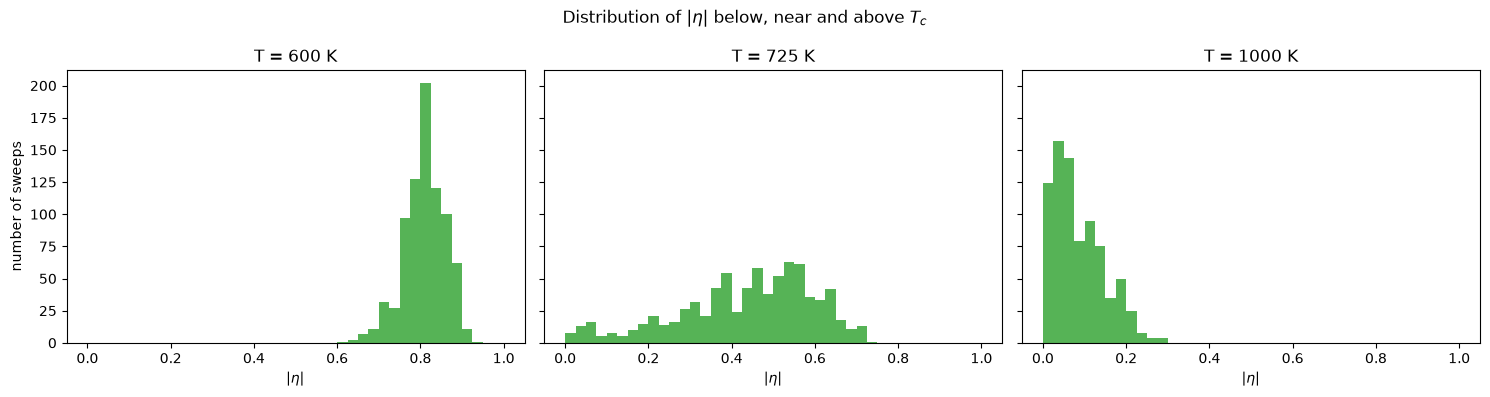

In [11]:
T_hist = [600, int(Tc_eta), 1000]

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, T in zip(axes, T_hist):
    ax.hist(series[T][1], bins=np.linspace(0, 1, 41), color="C2", alpha=0.8)
    ax.set_title(f"T = {T} K")
    ax.set_xlabel(r"$|\eta|$")
axes[0].set_ylabel("number of sweeps")
fig.suptitle(r"Distribution of $|\eta|$ below, near and above $T_c$")
fig.tight_layout()
plt.show()

Below $T_c$ the distribution is narrow around a large value of $|\eta|$ (ordered phase); above $T_c$ it is concentrated near the finite-size floor (disordered phase). Near $T_c$ it is very broad: the system wanders between ordered and disordered states, which is also why the heat capacity is maximal there.

**Limits of these estimates.**
- The box is small ($L = 6$, 432 sites): the transition is rounded and slightly shifted, and $|\eta|$ never reaches 0.
- The temperature grid has a 25 K step around the transition, so $T_c$ is known to about $\pm 25$ K at best.
- Near $T_c$ the fluctuations are slow, so averages there are the least precise; longer runs or several independent runs would reduce the noise.
- The heat capacity is the noisiest quantity: it is the variance of a correlated series, so single points near $T_c$ can be off by 20-30 %, and the peak position moves by one or two grid points from run to run. For the final values, increase `N_MEAS` (e.g. 2000 or more), at least for the temperatures around the transition.

For comparison, the experimental order-disorder transition of $\beta$-brass is around 740 K.

In [12]:
print(f"{'T (K)':>6} {'E (eV/atom)':>12} {'C/(N kB)':>9} {'<|eta|>':>8} {'alpha_1':>8} {'alpha_2':>8}")
for k, T in enumerate(T_SCAN):
    print(f"{T:6d} {E_mean[k]:12.4f} {C[k]:9.3f} {eta_mean[k]:8.3f} {alpha_1_mean[k]:+8.3f} {alpha_2_mean[k]:+8.3f}")

 T (K)  E (eV/atom)  C/(N kB)  <|eta|>  alpha_1  alpha_2
   200      -2.4840     0.000    1.000   -1.000   +1.000
   300      -2.4840     0.007    1.000   -1.000   +0.999
   400      -2.4827     0.190    0.982   -0.966   +0.965
   500      -2.4780     0.530    0.915   -0.845   +0.840
   550      -2.4757     0.683    0.878   -0.786   +0.778
   600      -2.4719     1.122    0.810   -0.688   +0.672
   650      -2.4680     1.053    0.733   -0.588   +0.567
   675      -2.4639     1.610    0.628   -0.484   +0.454
   700      -2.4621     1.544    0.580   -0.437   +0.403
   725      -2.4582     1.381    0.434   -0.338   +0.296
   750      -2.4545     0.699    0.259   -0.242   +0.193
   775      -2.4539     0.497    0.232   -0.228   +0.177
   800      -2.4530     0.369    0.190   -0.205   +0.151
   850      -2.4516     0.195    0.131   -0.169   +0.117
   900      -2.4508     0.128    0.102   -0.148   +0.097
  1000      -2.4500     0.082    0.086   -0.126   +0.080
  1200      -2.4489     0.043  